In [59]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel(
    "../data/raw/logical_fallacy_dataset.xlsx",
    sheet_name="Dataset"
)

label_cols = df.columns[5:].tolist()

In [60]:
df["char_count"] = df["argument"].str.len()

df["word_count"] = df["argument"].str.split().str.len()

In [61]:
df[["char_count", "word_count"]].describe()

,char_count,word_count
count,17866.000000,17866.000000
mean,168.608362,27.256073
std,57.234207,9.188737
min,25.000000,4.000000
25%,127.000000,20.000000
50%,161.000000,26.000000
75%,205.000000,33.000000
max,697.000000,94.000000


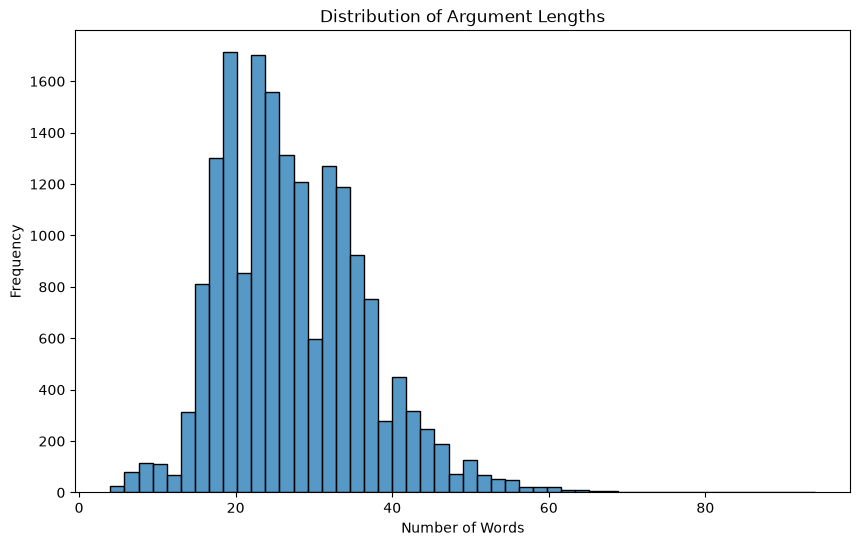

In [62]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="word_count",
    bins=50
)

plt.title("Distribution of Argument Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

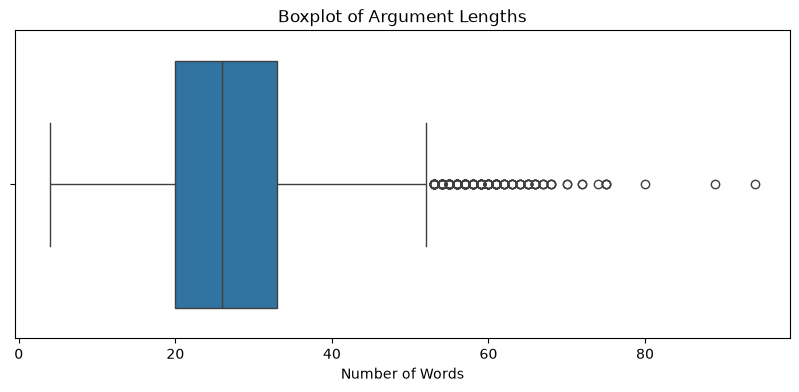

In [63]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df["word_count"])

plt.title("Boxplot of Argument Lengths")
plt.xlabel("Number of Words")

plt.show()

## Investigation B: Vocabulary Analysis

The objective is to understand the vocabulary characteristics
of the dataset, identify frequently occurring words and examine
the extent of vocabulary diversity.

In [64]:
all_text = " ".join(df["argument"])

all_words = all_text.lower().split()

print("Total word occurrences:", len(all_words))

print("First 30 words:", all_words[:30])

Total word occurrences: 486957
First 30 words: ['a', 'politician', 'declares:', "'recently,", 'there', 'have', 'been', 'two', 'criminal', 'cases', 'in', 'our', 'town', 'involving', 'outsiders.', 'clearly,', 'all', 'immigrants', 'are', 'dangerous!', 'to', 'protect', 'our', 'safety,', 'we', 'must', 'immediately', 'ban', 'all', 'outsiders']


In [65]:
from collections import Counter

word_freq = Counter(all_words)

print("Unique words:", len(word_freq))

word_freq.most_common(30)

Unique words: 16867


[('the', 12843),
 ('and', 12428),
 ('to', 11540),
 ('a', 7077),
 ('in', 6837),
 ('we', 6728),
 ('must', 6478),
 ('be', 6275),
 ('is', 5935),
 ('will', 5913),
 ('this', 5756),
 ('if', 5673),
 ('all', 5553),
 ('so', 4946),
 ('that', 4727),
 ('it', 4566),
 ('you', 4508),
 ('my', 4390),
 ('because', 3916),
 ('of', 3784),
 ('for', 3662),
 ('everyone', 3500),
 ('our', 3400),
 ('new', 3316),
 ('on', 3258),
 ('should', 2762),
 ('therefore,', 2682),
 ('are', 2660),
 ('since', 2465),
 ('students', 2337)]

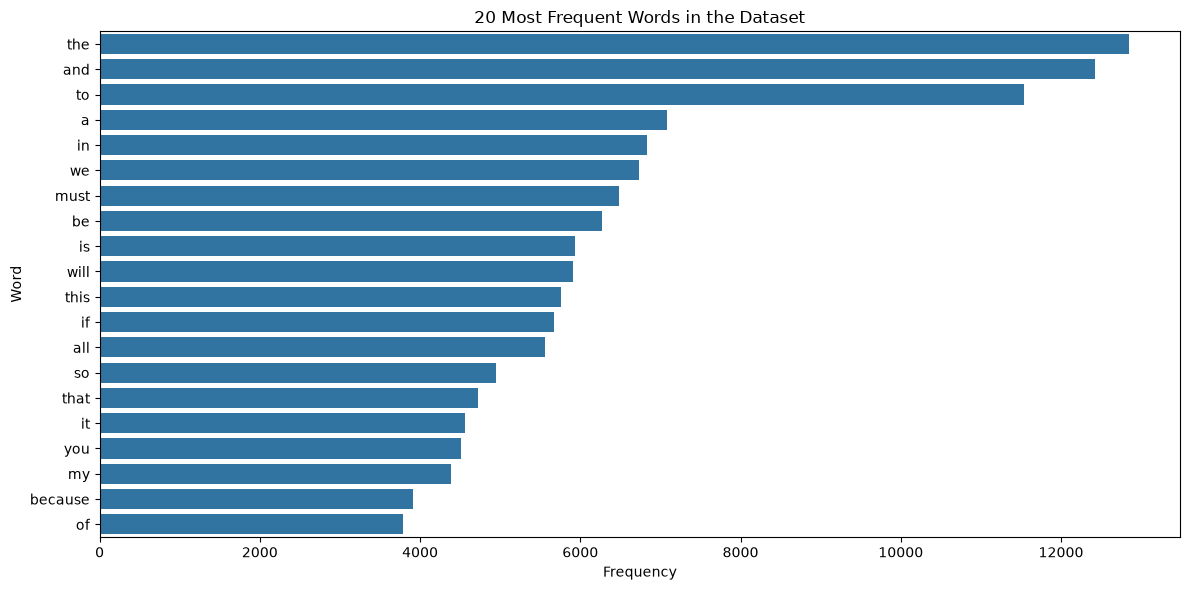

In [66]:
top_words = word_freq.most_common(20)

words = [item[0] for item in top_words]
frequencies = [item[1] for item in top_words]

plt.figure(figsize=(12, 6))

sns.barplot(
    x=frequencies,
    y=words
)

plt.title("20 Most Frequent Words in the Dataset")
plt.xlabel("Frequency")
plt.ylabel("Word")

plt.tight_layout()
plt.show()

In [67]:
import re

all_words_clean = re.findall(
    r"\b[a-z]+(?:'[a-z]+)?\b",
    all_text.lower()
)

word_freq_clean = Counter(all_words_clean)

print("Total tokens:", len(all_words_clean))
print("Unique words:", len(word_freq_clean))

print(word_freq_clean.most_common(30))

Total tokens: 486663
Unique words: 9213
[('the', 12851), ('and', 12451), ('to', 11569), ('a', 7193), ('in', 6884), ('we', 6734), ('must', 6481), ('be', 6284), ('is', 5949), ('will', 5920), ('all', 5895), ('this', 5884), ('it', 5842), ('if', 5682), ('so', 5268), ('that', 4749), ('you', 4599), ('my', 4392), ('because', 3919), ('everyone', 3832), ('of', 3785), ('for', 3666), ('our', 3403), ('new', 3317), ('on', 3269), ('therefore', 3171), ('should', 2762), ('are', 2666), ('since', 2470), ('use', 2402)]


In [68]:
slippery_slope_text = df[df["Slippery Slope"] == 1]["argument"]

ad_hominem_text = df[df["Ad Hominem"] == 1]["argument"]

bandwagon_text = df[df["Bandwagon / Popularity"] == 1]["argument"]

In [69]:
def get_word_frequencies(text_series):

    text = " ".join(text_series)

    words = re.findall(r"\b[a-z]+\b", text.lower())

    return Counter(words)

ss_freq = get_word_frequencies(slippery_slope_text)

ah_freq = get_word_frequencies(ad_hominem_text)

bw_freq = get_word_frequencies(bandwagon_text)

print("SLIPPERY SLOPE")
print(ss_freq.most_common(20))

print("\nAD HOMINEM")
print(ah_freq.most_common(20))

print("\nBANDWAGON")
print(bw_freq.most_common(20))

SLIPPERY SLOPE
[('to', 6497), ('and', 5439), ('we', 4696), ('will', 3912), ('if', 3868), ('in', 2899), ('they', 2647), ('the', 2563), ('ll', 2288), ('all', 2191), ('allow', 2169), ('students', 2112), ('a', 2107), ('use', 2036), ('math', 2004), ('become', 1856), ('eventually', 1849), ('on', 1841), ('it', 1833), ('calculators', 1707)]

AD HOMINEM
[('and', 957), ('the', 873), ('is', 729), ('s', 726), ('a', 671), ('it', 631), ('to', 576), ('be', 554), ('t', 537), ('who', 532), ('we', 489), ('because', 467), ('that', 466), ('so', 460), ('must', 457), ('everyone', 415), ('he', 410), ('you', 408), ('in', 346), ('new', 345)]

BANDWAGON
[('it', 3021), ('and', 2658), ('the', 2520), ('everyone', 2031), ('you', 1961), ('must', 1547), ('be', 1524), ('is', 1504), ('to', 1483), ('this', 1290), ('so', 1258), ('s', 1248), ('because', 1130), ('we', 1107), ('that', 1101), ('my', 1088), ('all', 1076), ('a', 1055), ('new', 1028), ('in', 1024)]


In [70]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

print("Number of stopwords:", len(ENGLISH_STOP_WORDS))

Number of stopwords: 318


In [71]:
import re

def remove_stopwords(text):

    words = re.findall(
        r"\b[a-z]+(?:'[a-z]+)?\b",
        text.lower()
    )

    filtered_words = [
        word for word in words
        if word not in ENGLISH_STOP_WORDS
    ]

    return filtered_words

In [72]:
df["cleaned_words"] = df["argument"].apply(remove_stopwords)

df[["argument", "cleaned_words"]].head()

,argument,cleaned_words
0,"A politician declares: 'Recently, there have been two criminal cases in our town involving outsiders. Clearly, all immigrants are dangerous! To protect our safety, we must immediately ban all outsiders from entering, or else your families will be in danger!'","[politician, declares, recently, criminal, cases, town, involving, outsiders, clearly, immigrants, dangerous, protect, safety, immediately, ban, outsiders, entering, families, danger]"
1,"A commentator claims: 'If we allow students to use tablets in class to take notes, the next thing you know, they’ll get addicted to entertainment, stop studying, their grades will collapse, and soon we’ll raise an ignorant generation that leads society to ruin! And anyone who supports using tablets in class is utterly stupid.'","[commentator, claims, allow, students, use, tablets, class, notes, thing, know, ll, addicted, entertainment, stop, studying, grades, collapse, soon, ll, raise, ignorant, generation, leads, society, ruin, supports, using, tablets, class, utterly, stupid]"
2,"A famous actor in a commercial says: 'I drink Brand X fruit and vegetable juice every morning. Look at how successful I am now! I owe my success to this juice. So trust me—if you drink it every day, you’ll be successful too.'","[famous, actor, commercial, says, drink, brand, x, fruit, vegetable, juice, morning, look, successful, owe, success, juice, trust, drink, day, ll, successful]"
3,"A concerned parent says: 'I heard about a teenager who became violent after playing a video game. All these games are obviously corrupting our youth. If I let my son play any video games, he might become a criminal too. We should ban video games to protect our children from this danger.'","[concerned, parent, says, heard, teenager, violent, playing, video, game, games, obviously, corrupting, youth, let, son, play, video, games, criminal, ban, video, games, protect, children, danger]"
4,"As a renowned scientist, Dr. Smith claims that this new energy drink is completely safe because millions of people are already drinking it daily, and if you disagree, you must be against scientific progress and consumer choice","[renowned, scientist, dr, smith, claims, new, energy, drink, completely, safe, millions, people, drinking, daily, disagree, scientific, progress, consumer, choice]"


In [73]:
all_cleaned_words = [
    word
    for words in df["cleaned_words"]
    for word in words
]

cleaned_word_freq = Counter(all_cleaned_words)

print("Total words after stopword removal:", len(all_cleaned_words))

print("Unique words after stopword removal:", len(cleaned_word_freq))

print(cleaned_word_freq.most_common(30))

Total words after stopword removal: 263803
Unique words after stopword removal: 8950
[('new', 3317), ('use', 2402), ('students', 2380), ("don't", 2239), ('allow', 2200), ('math', 2071), ('collapse', 1938), ('eventually', 1896), ('calculators', 1723), ('class', 1706), ('basic', 1650), ('technology', 1576), ('arithmetic', 1489), ('people', 1472), ("it's", 1427), ('says', 1425), ("they'll", 1374), ('immediately', 1373), ('clearly', 1352), ('policy', 1349), ('entire', 1252), ('dependent', 1216), ('lead', 1162), ('soon', 1105), ('completely', 1105), ('just', 1050), ('lose', 1043), ('dr', 1033), ('ban', 993), ('energy', 958)]


In [74]:
calculator_arguments = df[
    (df["Slippery Slope"] == 1) &
    (df["argument"].str.contains(r"\bcalculators?\b", case=False, na=False))
]

In [75]:
print("Total matching arguments:", len(calculator_arguments))

pd.set_option("display.max_colwidth", None)
calculator_arguments[["id", "argument", "fallacies"]]

Total matching arguments: 1654


,id,argument,fallacies
90,91,"If we allow students to use calculators in math class, soon they'll forget how to do basic arithmetic. Then they won't be able to balance their checkbooks, which will lead to financial ruin for the entire generation. Everyone agrees this technology is destroying our children's future.",Slippery Slope; Bandwagon / Popularity
244,246,"If we allow students to use calculators in math class, soon they won't be able to do basic arithmetic, and then they'll fail all their exams, which will prove that our education system is collapsing because everyone knows calculators make people lazy.",Slippery Slope; Appeal to Authority
247,249,"Everyone knows that if we allow students to use calculators in math class, they'll become completely dependent on technology, lose all basic arithmetic skills, and eventually society will collapse into mathematical illiteracy. This is what all the top educators are warning us about.",Slippery Slope; Appeal to Authority
301,303,"My professor says that if we allow students to use calculators on this basic math test, soon they'll become completely dependent on technology and lose all fundamental math skills, leading to the collapse of our entire education system. Everyone in the faculty agrees with this alarming prediction.",Slippery Slope; Bandwagon / Popularity
436,438,"If we allow students to use calculators in math class, soon they'll forget basic arithmetic entirely, and then everyone will fail because even Einstein said relying on tools weakens the mind.",Slippery Slope; Appeal to Authority
...,...,...,...
17841,20002,"If we allow students to use calculators in math class, they might rely on them too much, then forget basic arithmetic, then fail to function in daily life without technology, and eventually become completely dependent on machines for all thinking.",Slippery Slope
17842,20003,"If we allow students to use calculators in math class, they might start relying on technology for all thinking, eventually becoming unable to solve basic problems without digital assistance.",Slippery Slope
17844,20005,"If we allow students to use calculators in math class, they might become dependent on technology and eventually lose all ability to do mental arithmetic, leading to a generation that can't even count properly.",Slippery Slope
17849,20010,"If we allow students to use calculators in math class, they'll become dependent on technology, stop learning basic arithmetic, fail to develop critical thinking skills, and eventually society will collapse because no one can do mental math anymore.",Slippery Slope


In [76]:
calculator_mask = df["argument"].str.contains(
    r"\bcalculators?\b",
    case=False,
    na=False
)

calculator_df = df[calculator_mask]

print("Total calculator arguments:", len(calculator_df))

Total calculator arguments: 1744


In [77]:
calculator_df["fallacies"].value_counts().head(15)

fallacies
Slippery Slope                             1579
Hasty Generalization                         79
Slippery Slope; Appeal to Emotion            30
Slippery Slope; Appeal to Authority          17
Slippery Slope; Bandwagon / Popularity        9
Slippery Slope; False Dilemma                 7
Slippery Slope; False Cause / Causality       6
Slippery Slope; Hasty Generalization          3
False Cause / Causality                       2
Circular Reasoning                            2
Equivocation                                  2
Slippery Slope; Equivocation                  2
Hasty Generalization; Appeal to Emotion       2
Ad Hominem                                    1
Hasty Generalization; False Dilemma           1
Name: count, dtype: int64

In [78]:
calculator_df["split"].value_counts()

calculator_freq = get_word_frequencies(
    calculator_df["argument"]
)

calculator_freq.most_common(30)

[('to', 3615),
 ('math', 1971),
 ('they', 1867),
 ('calculators', 1723),
 ('we', 1654),
 ('students', 1648),
 ('use', 1639),
 ('if', 1629),
 ('in', 1614),
 ('basic', 1599),
 ('allow', 1590),
 ('and', 1589),
 ('arithmetic', 1489),
 ('on', 1451),
 ('class', 1310),
 ('become', 1282),
 ('technology', 1255),
 ('dependent', 1176),
 ('eventually', 1159),
 ('ll', 866),
 ('for', 809),
 ('will', 800),
 ('forget', 754),
 ('do', 737),
 ('skills', 729),
 ('a', 671),
 ('might', 667),
 ('simple', 649),
 ('lose', 632),
 ('all', 588)]

In [79]:
calculator_df["split"].value_counts()

split
train    1374
val       191
test      179
Name: count, dtype: int64

In [80]:
pd.crosstab(
    calculator_df["split"],
    calculator_df["Slippery Slope"]
)

Slippery Slope,0,1
split,,
test,8,171
train,72,1302
val,10,181


In [81]:
calculator_df = calculator_df.copy()

calculator_df["opening"] = calculator_df["argument"].apply(
    lambda x: " ".join(x.lower().split()[:10])
)

calculator_df["opening"].value_counts().head(20)

opening
if we allow students to use calculators in math class,                                1242
if we allow students to use calculators for basic arithmetic,                          121
if we allow students to use calculators for basic math,                                 92
if we allow students to use calculators for simple arithmetic,                          24
if we allow students to use calculators for simple math,                                14
my neighbor's solar-powered calculator works fine, so all electronic devices            13
if students are allowed to use calculators in math class,                               12
if we allow one student to use a calculator during                                       7
if we allow students to use calculators in math class                                    7
if we start allowing students to use calculators in math                                 7
if we allow students to use calculators in basic math                             

In [82]:
print(
    "Unique openings:",
    calculator_df["opening"].nunique()
)

print(
    "Total arguments:",
    len(calculator_df)
)

Unique openings: 151
Total arguments: 1744


In [83]:
for split_name in ["train", "val", "test"]:

    print(f"\n{'='*30}")
    print(split_name.upper())
    print('='*30)

    sample = calculator_df[
        calculator_df["split"] == split_name
    ].sample(
        min(5, len(calculator_df)),
        random_state=42
    )

    for argument in sample["argument"]:
        print("\n", argument)


TRAIN

 If we allow students to use calculators for basic math, they will become dependent on technology and eventually lose all ability to perform mental calculations.

 If we allow students to use calculators in math class, they might become dependent on technology and eventually lose all basic arithmetic skills, leading to a society where no one can do simple math without devices.

 If we allow students to use calculators for basic arithmetic, soon they'll forget how to do mental math, then they'll become dependent on technology for all thinking, and eventually human intelligence will decline to primitive levels.

 My neighbor's solar-powered calculator stopped working after a month, so solar-powered devices are unreliable.

 If we allow students to use calculators in basic math class, they might become dependent on technology for simple calculations, which could lead to a decline in mental arithmetic skills, then poor performance in advanced math, and ultimately diminish their car

In [84]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [85]:
def custom_tokenizer(text):

    return re.findall(
        r"\b[a-z]+(?:'[a-z]+)?\b",
        text.lower()
    )

In [86]:
calculator_vectorizer = TfidfVectorizer(
    tokenizer=custom_tokenizer,
    token_pattern=None,
    stop_words=None,
    ngram_range=(1, 2)
)

calculator_matrix = calculator_vectorizer.fit_transform(
    calculator_df["argument"]
)

print("Matrix shape:", calculator_matrix.shape)

Matrix shape: (1744, 4224)


In [87]:
arg1 = calculator_df["argument"].iloc[0]

arg2 = calculator_df["argument"].iloc[1]

vectors = calculator_vectorizer.transform([arg1, arg2])

similarity = cosine_similarity(vectors[0], vectors[1])

print(similarity[0, 0])

0.16550221905854998


In [88]:
print("ARGUMENT 1:")
print(arg1)

print("\nARGUMENT 2:")
print(arg2)

print("\nCOSINE SIMILARITY:")
print(similarity[0, 0])

ARGUMENT 1:
If we allow students to use calculators in math class, soon they'll forget how to do basic arithmetic. Then they won't be able to balance their checkbooks, which will lead to financial ruin for the entire generation. Everyone agrees this technology is destroying our children's future.

ARGUMENT 2:
If we allow students to use calculators in math class, soon they won't be able to do basic arithmetic, and then they'll fail all their exams, which will prove that our education system is collapsing because everyone knows calculators make people lazy.

COSINE SIMILARITY:
0.16550221905854998


In [89]:
features = calculator_vectorizer.get_feature_names_out()

nonzero_1 = set(vectors[0].indices)
nonzero_2 = set(vectors[1].indices)

shared_features = nonzero_1.intersection(nonzero_2)

print("Features in argument 1:", len(nonzero_1))
print("Features in argument 2:", len(nonzero_2))
print("Shared features:", len(shared_features))

print("Shared vocabulary:")

for idx in shared_features:
    print(features[idx])

Features in argument 1: 88
Features in argument 2: 81
Shared features: 44
Shared vocabulary:
calculators
in math
then
calculators in
to
we
we allow
do
do basic
class
soon
to do
class soon
their
they
basic
able
able to
basic arithmetic
everyone
they won't
they'll
allow
allow students
won't
won't be
which
be
if
be able
which will
if we
math
our
arithmetic
math class
to use
use
students
use calculators
in
will
students to
is


In [90]:
shared_feature_scores = []

for idx in shared_features:

    weight_1 = vectors[0, idx]

    weight_2 = vectors[1, idx]

    contribution = weight_1 * weight_2

    shared_feature_scores.append(
        (features[idx], weight_1, weight_2, contribution)
    )

shared_feature_scores.sort(
    key=lambda x: x[3],
    reverse=True
)

for feature, w1, w2, contribution in shared_feature_scores:

    print(
        f"{feature:25} "
        f"A: {w1:.4f} "
        f"B: {w2:.4f} "
        f"Contribution: {contribution:.6f}"
    )

is                        A: 0.1329 B: 0.1342 Contribution: 0.017825
everyone                  A: 0.1282 B: 0.1295 Contribution: 0.016607
which will                A: 0.1016 B: 0.1026 Contribution: 0.010417
our                       A: 0.0878 B: 0.0887 Contribution: 0.007788
they won't                A: 0.0862 B: 0.0870 Contribution: 0.007497
won't be                  A: 0.0845 B: 0.0853 Contribution: 0.007203
won't                     A: 0.0826 B: 0.0834 Contribution: 0.006886
able                      A: 0.0822 B: 0.0830 Contribution: 0.006818
able to                   A: 0.0822 B: 0.0830 Contribution: 0.006818
be able                   A: 0.0822 B: 0.0830 Contribution: 0.006818
class soon                A: 0.0786 B: 0.0794 Contribution: 0.006238
do basic                  A: 0.0769 B: 0.0776 Contribution: 0.005968
which                     A: 0.0748 B: 0.0756 Contribution: 0.005657
to                        A: 0.1058 B: 0.0534 Contribution: 0.005648
be                        A: 0.074

In [91]:
from sklearn.feature_extraction.text import CountVectorizer

count_vectorizer = CountVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2),
    binary=True
)

count_matrix = count_vectorizer.fit_transform(
    [arg1, arg2]
)

binary_similarity = cosine_similarity(
    count_matrix[0],
    count_matrix[1]
)

print("Binary cosine similarity:", binary_similarity[0, 0])

Binary cosine similarity: 0.4408667141774056


In [92]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
similarity_matrix = cosine_similarity(calculator_matrix)
upper_triangle = np.triu(similarity_matrix, k=1)
highly_similar = np.sum(upper_triangle >= 0.8)
print("Number of highly similar pairs:", highly_similar)


Number of highly similar pairs: 843


In [93]:
import numpy as np

# Get indices of pairs with similarity >= 0.8
rows, cols = np.where(np.triu(similarity_matrix, k=1) >= 0.8)

# Sort pairs by similarity (highest first)
sorted_indices = np.argsort(similarity_matrix[rows, cols])[::-1]

# Display the top 10 pairs
for idx in sorted_indices[:10]:

    i = rows[idx]
    j = cols[idx]

    print("=" * 100)
    print("Similarity:", similarity_matrix[i, j])

    print("\nArgument 1:")
    print(calculator_df["argument"].iloc[i])

    print("\nArgument 2:")
    print(calculator_df["argument"].iloc[j])

    print("\nSplits:", calculator_df["split"].iloc[i],
          "|", calculator_df["split"].iloc[j])

    print("\nLabels:", calculator_df["fallacies"].iloc[i],
          "|", calculator_df["fallacies"].iloc[j])

Similarity: 0.9756670741549057

Argument 1:
If we allow students to use calculators in math class, they'll forget basic arithmetic, then fail to balance their checkbooks, and eventually the entire economy will collapse due to financial illiteracy.

Argument 2:
If we allow students to use calculators in math class, soon they'll forget basic arithmetic, then fail to balance their checkbooks, and eventually the entire economy will collapse due to financial illiteracy.

Splits: val | train

Labels: Slippery Slope | Slippery Slope
Similarity: 0.9714404423788997

Argument 1:
If we allow students to use calculators in math class, they might become dependent on technology and forget basic arithmetic skills, which could lead to a generation unable to do mental math, ultimately causing society's mathematical literacy to collapse.

Argument 2:
If we allow students to use calculators in math class, they'll become dependent on technology and forget basic arithmetic skills, which could lead to a gen

In [94]:
# Create a DataFrame containing all highly similar pairs

import pandas as pd
import numpy as np

rows, cols = np.where(np.triu(similarity_matrix, k=1) >= 0.8)

pairs_df = pd.DataFrame({
    "argument_1": calculator_df["argument"].iloc[rows].values,
    "argument_2": calculator_df["argument"].iloc[cols].values,
    "similarity": similarity_matrix[rows, cols],
    "split_1": calculator_df["split"].iloc[rows].values,
    "split_2": calculator_df["split"].iloc[cols].values,
    "label_1": calculator_df["fallacies"].iloc[rows].values,
    "label_2": calculator_df["fallacies"].iloc[cols].values
})

# Check whether pairs belong to different splits
pairs_df["cross_split"] = pairs_df["split_1"] != pairs_df["split_2"]

# Summarise results
print("Total highly similar pairs:", len(pairs_df))

print("\nCross-split pairs:")
print(pairs_df["cross_split"].value_counts())

print("\nSimilarity >= 0.95:")
print((pairs_df["similarity"] >= 0.95).sum())

print("\nCross-split pairs with similarity >= 0.95:")
print(
    (
        (pairs_df["similarity"] >= 0.95) &
        (pairs_df["cross_split"])
    ).sum()
)

print("\nSame fallacy labels:")
print((pairs_df["label_1"] == pairs_df["label_2"]).sum())

Total highly similar pairs: 843

Cross-split pairs:
cross_split
False    575
True     268
Name: count, dtype: int64

Similarity >= 0.95:
17

Cross-split pairs with similarity >= 0.95:
7

Same fallacy labels:
835


In [95]:
near_duplicates = pairs_df[
    (pairs_df["similarity"] >= 0.95) &
    (pairs_df["cross_split"] == True)
].sort_values("similarity", ascending=False)

for _, row in near_duplicates.iterrows():

    print("=" * 100)
    print("Similarity:", row["similarity"])

    print("\nArgument 1:", row["argument_1"])
    print("Split:", row["split_1"])
    print("Label:", row["label_1"])

    print("\nArgument 2:", row["argument_2"])
    print("Split:", row["split_2"])
    print("Label:", row["label_2"])

Similarity: 0.9756670741549057

Argument 1: If we allow students to use calculators in math class, they'll forget basic arithmetic, then fail to balance their checkbooks, and eventually the entire economy will collapse due to financial illiteracy.
Split: val
Label: Slippery Slope

Argument 2: If we allow students to use calculators in math class, soon they'll forget basic arithmetic, then fail to balance their checkbooks, and eventually the entire economy will collapse due to financial illiteracy.
Split: train
Label: Slippery Slope
Similarity: 0.9714404423788997

Argument 1: If we allow students to use calculators in math class, they might become dependent on technology and forget basic arithmetic skills, which could lead to a generation unable to do mental math, ultimately causing society's mathematical literacy to collapse.
Split: test
Label: Slippery Slope

Argument 2: If we allow students to use calculators in math class, they'll become dependent on technology and forget basic arit

In [96]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

full_vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2),
    max_features=50000
)

full_matrix = full_vectorizer.fit_transform(df["argument"])

print("Matrix shape:", full_matrix.shape)

Matrix shape: (17866, 50000)


In [97]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

batch_size = 500
threshold = 0.80

similar_pairs = []

n = full_matrix.shape[0]

for start in range(0, n, batch_size):

    end = min(start + batch_size, n)

    # Calculate similarities between this batch and the entire dataset
    similarity_batch = cosine_similarity(
        full_matrix[start:end],
        full_matrix
    )

    # Examine only unique pairs (upper triangle)
    for i in range(end - start):

        global_i = start + i

        # Only consider arguments appearing after the current argument
        similarities = similarity_batch[i, global_i + 1:]

        # Find arguments with similarity >= threshold
        matching_indices = np.where(similarities >= threshold)[0]

        for j in matching_indices:

            global_j = global_i + 1 + j

            similar_pairs.append((
                global_i,
                global_j,
                similarity_batch[i, global_j]
            ))

    print(f"Processed {end}/{n} arguments")

print("\nTotal highly similar pairs:", len(similar_pairs))

Processed 500/17866 arguments
Processed 1000/17866 arguments
Processed 1500/17866 arguments
Processed 2000/17866 arguments
Processed 2500/17866 arguments
Processed 3000/17866 arguments
Processed 3500/17866 arguments
Processed 4000/17866 arguments
Processed 4500/17866 arguments
Processed 5000/17866 arguments
Processed 5500/17866 arguments
Processed 6000/17866 arguments
Processed 6500/17866 arguments
Processed 7000/17866 arguments
Processed 7500/17866 arguments
Processed 8000/17866 arguments
Processed 8500/17866 arguments
Processed 9000/17866 arguments
Processed 9500/17866 arguments
Processed 10000/17866 arguments
Processed 10500/17866 arguments
Processed 11000/17866 arguments
Processed 11500/17866 arguments
Processed 12000/17866 arguments
Processed 12500/17866 arguments
Processed 13000/17866 arguments
Processed 13500/17866 arguments
Processed 14000/17866 arguments
Processed 14500/17866 arguments
Processed 15000/17866 arguments
Processed 15500/17866 arguments
Processed 16000/17866 argume